---
title: "The bubbling bed, and the conversion ceiling nobody can buy their way past"
description: "Kunii and Levenspiel's 1968 model of a fluidized bed reduces to one algebraic expression. Reproducing their three worked appendices verifies it, and then the same expression says a bed cannot exceed 99.1 % conversion however good the catalyst is."
categories: [sec:E, struct:S7, tier:T0, data:tier6, phase:gas-solid]
date: 2026-07-30
---

# The bubbling bed, and the conversion ceiling nobody can buy their way past

**Catalog ID:** `E2.1` · **Structures:** `S7` (multiphase coupling) · **Tier:** T0

A fluidized bed is the only common reactor that routinely converts **less than a
perfectly stirred tank**. Feed a catalytic bed hard enough and conversion stops
responding to the catalyst altogether: gas rides up inside bubbles, and bubbles
have almost no catalyst in them.

Kunii and Levenspiel's 1968 paper is where that behaviour got a quantitative
model with **one adjustable parameter**, the effective bubble diameter, instead
of the six that competing two-region models needed. This page reproduces it,
checks it against the three worked examples the authors printed, asks the
question the model answers but the paper never states (*how good can a bubbling
bed get?*), and then puts back the gas transport in the cloud and the emulsion
that the published model leaves out.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.03.2"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "E2.1-kunii-levenspiel-bubbling-bed"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page's model.py is put on sys.path by setup().
import numpy as np
import matplotlib.pyplot as plt
from pymrm.checks import find_roots, observed_orders
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (KL, BubblingBed, Kf_closed, Kf_over_Km, Kr_of_Km, appendix_A,
                   appendix_B, backmix_crossing, ceiling_Kf, extended_exact,
                   hydrodynamics, velocities)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
EPS = np.finfo(float).eps
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))

## Background

Above minimum fluidization the excess gas travels as **bubbles**. A fast bubble
drags a thin shell of emulsion round with it, the **cloud**, plus a **wake** of
solids behind it, and the whole assembly rises faster than the gas percolating
through the emulsion. Fresh reactant therefore enters the bed almost entirely
inside bubbles, which contain hardly any catalyst, and it can only react after
crossing into the cloud and then into the emulsion.

That gives a chain of resistances in series and parallel:

| step | rate coefficient |
|---|---|
| reaction on the few solids dispersed *in* the bubble | $\gamma_b K_r$ |
| interchange bubble $\to$ cloud+wake | $K_{bc}$ |
| reaction on the solids in the cloud+wake | $\gamma_c K_r$ |
| interchange cloud $\to$ emulsion | $K_{ce}$ |
| reaction on the solids in the emulsion | $\gamma_e K_r$ |

Every one of these follows from **one** fitted quantity, the effective bubble
size $d_b$. That is the claim of the paper, and it is what makes the model
usable: the same $d_b$ has to explain gas–solid mass transfer, gas–solid heat
transfer *and* catalytic conversion, and the paper works all three.

Two of the older explanations are worth naming because the model has to beat
them. Tanks-in-series and axial-dispersion models can only produce conversions
**between** plug flow and backmix flow; measured beds routinely fall below
backmix. And a dozen two-region models with up to six parameters could each fit
one data set and no other.

## The published model

Everything below was read off 600 dpi renders of the printed pages. The scan's
text layer renders equations 49, 50 and 56 as loose fragments and drops decimal
points (appendix C's $13.2\,\mathcal{K}_m$ comes out as `1.32 K_m`), so it was
not used. Equation numbers are the paper's.

**Flow.** With $u_0 > 2u_{mf}$ only large fast bubbles survive, and

$$
\delta = \frac{u_0-u_{mf}}{u_b},\qquad
u_b = u_0 - u_{mf} + u_{br},\qquad
u_{br} = 0.711\,(g d_b)^{1/2}
\tag{2, 3, 51}
$$

$$
1-\delta = \frac{L_{mf}}{L_f} = \frac{1-\varepsilon_f}{1-\varepsilon_{mf}},
\qquad
\frac{L_{mf}}{L_m} = \frac{1-\varepsilon_m}{1-\varepsilon_{mf}}
\tag{4}
$$

**Interchange**, per unit bubble volume per second:

$$
K_{bc} = 4.5\left(\frac{u_{mf}}{d_b}\right) + 5.85\,\frac{\mathfrak{D}^{1/2}g^{1/4}}{d_b^{5/4}},
\qquad
K_{ce} \cong 6.78\left(\frac{\varepsilon_{mf}\mathfrak{D}_e u_b}{d_b^{3}}\right)^{1/2}
\tag{10, 12}
$$

**Solids distribution**, as volume of solids per volume of bubble:

$$
\gamma_b \cong 0.001\text{–}0.01,
\qquad
\gamma_c = (1-\varepsilon_{mf})\left(\frac{3u_{mf}/\varepsilon_{mf}}{0.711(gd_b)^{1/2}-u_{mf}/\varepsilon_{mf}} + \alpha\right),
$$
$$
\delta(\gamma_b+\gamma_c+\gamma_e) = (1-\varepsilon_{mf})(1-\delta)
\tag{15, 16, 17}
$$

with $\alpha = V_w/V_b$ the wake-to-bubble volume ratio, 0.25–0.4 by equation 6.

**Reaction.** For a first-order reaction the three regions balance as

$$
-u_b\frac{dC_{Ab}}{dl} = (K_r)_b C_{Ab} = \gamma_b K_r C_{Ab} + K_{bc}(C_{Ab}-C_{Ac})
\tag{48a}
$$
$$
K_{bc}(C_{Ab}-C_{Ac}) \cong \gamma_c K_r C_{Ac} + K_{ce}(C_{Ac}-C_{Ae}),
\qquad
K_{ce}(C_{Ac}-C_{Ae}) \cong \gamma_e K_r C_{Ae}
\tag{48b, 48c}
$$

Equations 48b and 48c are **algebraic**: the cloud and the emulsion are assumed
to be in local steady state, with no axial transport of their own. Eliminating
$C_{Ac}$ and $C_{Ae}$ collapses the whole reactor to one number:

$$
\mathcal{K}_f = (K_r)_b\left(\frac{L_f}{u_b}\right)
= K_r\left(\frac{L_f}{u_b}\right)
\left[\gamma_b + \cfrac{1}{\cfrac{K_r}{K_{bc}} + \cfrac{1}{\gamma_c + \cfrac{1}{\cfrac{K_r}{K_{ce}}+\cfrac{1}{\gamma_e}}}}\right]
\tag{49}
$$

$$
K_r\left(\frac{L_f}{u_b}\right) = \frac{1}{1-\varepsilon_{mf}}\left(\frac{u_0}{u_{br}}\right)\mathcal{K}_m,
\qquad
\mathcal{K}_m = (1-\varepsilon_m)K_r L_m/u_0
\tag{50, 45}
$$

and the exit gas, taken to be bubble gas only, gives

$$
1 - X_A = e^{-\mathcal{K}_f}
\tag{54}
$$

against $e^{-\mathcal{K}_m}$ for plug flow (eq. 42) and $1/(1+\mathcal{K}_m)$ for
backmix flow (eq. 46).

**This is algebra, not a differential equation.** The published model is a
continued fraction, and evaluating it needs numpy and nothing else. The
differential equation only comes back when the assumption behind equations 48b
and 48c is relaxed, which is what the PyMRM section below does.

### The same structure, three times over

The mass-transfer result (eq. 27), the heat-transfer result (eq. 38) and the
reaction result are the *same* expression with $B_d$, $H_{bc}$ or $K_r$ in the
reacting slot:

$$
(\mathrm{Sh})_{\text{over-all}} \cong \frac{\delta}{1-\varepsilon_f}
\left[\gamma_b(\mathrm{Sh}^*)_t + \frac{y\varphi_s d_p^2}{6\mathfrak{D}}K_{bc}\right],
\qquad
\mathrm{Nu}_{\text{apparent}} \cong \frac{1}{1-\varepsilon_f}
\left[\gamma_b(\mathrm{Nu}^*)_t + \frac{\varphi_s d_p^2}{6k_g}H_{bc}\right]
$$

The two prefactors differ deliberately: the text says equation 38 was obtained
after "replacing $u_b$ by $u_0/\delta$", which cancels the $\delta$. The local
coefficients come from the single-sphere correlation, equation 1,
$\mathrm{Sh}^* = 2 + 0.6\,\mathrm{Sc}^{1/3}\mathrm{Re}^{1/2}$, evaluated at the
particle's terminal velocity.

## Parameters and assumptions

Three worked examples are printed as appendices, and between them they exercise
every equation above. Their inputs, as printed, are in the dataset's sidecar and
in the cell below; the one used throughout the reaction sections is
**appendix C**, Kobayashi and Arai's ozone-decomposition bed.

**Assumptions that matter.** The emulsion stays exactly at minimum fluidizing
conditions at every gas velocity; all bubbles have one size; bubbles are
solid-free apart from $\gamma_b$; the exit stream is bubble gas only. And
$\alpha = 0.47$ here sits *outside* the 0.25–0.40 range equation 6 quotes: the
paper takes it from a different source and says so.

**Two printed slips, recorded rather than repaired.** Appendix C prints
$u_0 = (6.6+9.9+13.2+20)/5 = 13.2$, four terms over five. The value 13.2 is used
everywhere downstream and is confirmed by the paper's own
$u_b = 13.2-2.1+42.8 = 53.9$, so nothing is in doubt; a term was dropped in
typesetting. Appendix B prints $(1-\varepsilon_f)(u_0+5.8) = 8.70$ where its own
stated $\varepsilon_{mf} = 0.50$ gives a different number. Both are carried into
the dataset as printed, and the Validation section shows what each implies.

In [3]:
# Appendix C: Kobayashi and Arai's ozone bed, CGS, as printed.
C = dict(u0=13.2,      # cm/s, superficial gas velocity (the printed mean)
         umf=2.1,      # cm/s, minimum fluidisation
         emf=0.50,     # -, voidage at minimum fluidisation
         em=0.45,      # -, fixed-bed voidage
         Lm=34.0,      # cm, fixed-bed height
         db=3.7,       # cm, effective bubble diameter (fitted by the authors)
         alpha=0.47,   # -, wake fraction (Rowe and Partridge, 1965)
         D=0.204,      # cm^2/s, ozone in air, also used for the emulsion
         gamma_b=0.0)  # -, no solids in the bubbles
# Appendix A: smallest solid of Resnick and White (1949), gas-solid mass transfer.
A = dict(dp=0.028, phis=0.40, ut=41.0, D=0.065, y=0.9, Sc=2.39,
         umf=1.21, emf=0.50, gb=0.005, db=0.35)
# Appendix B: smallest solid of Heertjes and McKibbins, gas-solid heat transfer.
B = dict(dp=0.036, phis=0.806, ut=86.0, kg=6.25e-5, Cpg=0.24, Pr=0.69,
         umf=10.0, emf=0.50, gb=0.001, db=0.5)
KM_LIST = (0.5, 1.0, 2.0, 4.0, 8.0)   # the K_m range of the paper's figure 9

## The data

There is **no experimental data on this page**, and that is a deliberate choice.
The paper's experimental content is figures 3, 5, 7, 8 and 9, all scatter
plots that would have to be digitised. On figure 9, the sharpest of them, the
markers at low $\mathcal{K}_m$ overlap into a solid mass in which individual
centres cannot be located, so the extraction is staged for maintainer review
rather than published here.

What *is* loaded is a tier-6 reference set: **the numbers Kunii and Levenspiel
printed while working their own three appendices**, read off 600 dpi renders.
Reproducing them tests this reimplementation and the reading of the equations. It
does not test whether the model describes a real bed, and the page does not claim
otherwise. The same file is loaded by `E1.2`, which rebuilds the `4.5` of
equation 10 from a Davidson-bubble flow field.

In [4]:
ref = load_data("kunii_levenspiel_1968_appendix_values.csv", page=PAGE)
meta = load_meta("kunii_levenspiel_1968_appendix_values.csv", page=PAGE)
print(cite_data(meta))
print()
print(ref.to_string(index=False))


def printed(appendix, symbol):
    """The value as printed in the paper."""
    row = ref[(ref.appendix == appendix) & (ref.symbol == symbol)]
    return float(row.value.iloc[0])

Kunii, D.; Levenspiel, O. (1968) — Industrial & Engineering Chemistry Process Design and Development 7(4) 481-492 — doi:10.1021/i260028a001 — table

appendix                symbol                                                description    value        units
       A                  Re_t              particle Reynolds number at terminal velocity  7.54000            -
       A             Sh_star_t                 local Sherwood number from eq. (1) at Re_t  4.20000            -
       A                  K_bc      bubble-to-cloud interchange coefficient from eq. (10) 46.50000          1/s
       A           ub_minus_u0                rise velocity offset u_b - u_0 from eq. (3) 12.00000         cm/s
       A one_minus_ef_times_ub                         (1 - eps_f)(u_0 + 12) from eq. (4)  6.60000         cm/s
       A             Re_per_u0                                    Re/u_0 for these solids  0.18400         s/cm
       A           Sh_slope_u0                              slope o

## PyMRM implementation

Two layers, and they are different in character.

**The published model is closed form.** `hydrodynamics`, `Kf_closed` and
`ceiling_Kf` in `model.py` are equations 2, 3, 10, 12, 15, 17, 45, 49, 50 and 51
transcribed. No solver is involved and none is needed.

**The distributed model.** Equations 48b and 48c freeze the cloud and the
emulsion: they carry no gas, they only exchange sideways. The paper flags the
limitation itself: for $u_0/u_{mf} < 6\sim11$ the emulsion gas flows *upward*
and, in its words, "the conversion of emulsion gas will have to be found by an
extension of the present analysis". Kobayashi's runs are at
$u_0/u_{mf} = 3.1$–$9.6$, straddling that boundary.

`BubblingBed` solves all three regions as a **1-D convection–exchange system**
on the fluidized height, state `C` of shape `(n, 3)` (height first, then bubble,
cloud+wake, emulsion), with

* bubble gas at superficial velocity $v_b = u_0 - u_{mf}$ (equation 2),
* cloud+wake gas carried up **with the bubble** at $u_b$, so
  $v_c = \delta(V_c/V_b+\alpha)\varepsilon_{mf}u_b$,
* emulsion gas at whatever is left, $v_e = u_{mf} - v_c$, which is **negative**
  for these conditions: the emulsion gas flows down.

The last line is a closure choice and is stated as one: the three superficial
velocities are required to sum to $u_0$. The paper's own equations 5 and 7 give
an emulsion velocity too, from the solids circulation, and it does *not* satisfy
that balance; the Results section runs both.

Downflow makes this a two-point problem: the emulsion enters at the **top**,
carrying gas that has already been through the bed, and rejoins the feed at the
bottom. That recirculation loop is the flow pattern of the paper's figure 6, and
it is what the closed form cannot represent. The discretisation choices:

* **Each region has its own upwind operator**, `construct_convflux_upwind` on
  shape `(n, 1)` with that region's velocity, embedded in the `(n, 3)` system with
  `kron`. The regions need different boundaries: an inlet where the gas enters,
  `{"a": 0, "b": 1, "d": 1}` ($C = C_{\rm inlet}$), and `{"outflow": True}` where
  it leaves, which takes the outlet face value from the last cell, exact for a
  convection-only equation. With no outlet dictionary at all the matrix is
  singular; a zero-gradient outlet makes the upwind flux carry an extrapolated
  face value, and the Validation section shows what that does to the balance.
* **The recirculation is part of the linear system.** The inlet values enter
  through `shapes_d` as two extra unknowns, $C_{\rm in}$ at the bottom (feed
  mixed with the emulsion gas leaving there) and $C_{\rm top}$ at the top (the
  mixing cup of the gas leaving upward), with the two mixing equations as two
  extra rows. One `spsolve` gives profiles and loop together; nothing iterates.
* **The problem is linear**, so there is no `newton` and no `NumJac`: the
  transport operator is assembled once per grid in `__init__`, and each
  $\mathcal{K}_m$ adds its constant exchange block (equations 48a–c per unit bed
  volume) and solves once.

A linear system of three first-order ODEs also has an exact solution:
`extended_exact` writes it through the eigenmodes of $V^{-1}S$, each normalised
at the end where it is largest so that no exponential overflows, and solves five
linear equations for the mode amplitudes and the two loop values. It solves the
same equations as `BubblingBed`, so it checks the discretisation and the
assembly, not the model.

In [5]:
hC = hydrodynamics(**C)
print("Appendix C bed, recomputed from equations 2, 3, 10, 12, 15, 17, 51:")
for k in ("ubr", "ub", "delta", "Kbc", "Kce", "gc", "ge", "Lf"):
    print(f"  {k:6s} = {hC[k]:10.4f}")
print(f"  K_r    = {Kr_of_Km(1.0, hC):10.4f} x K_m")
v_bal = velocities(hC)
v_pap = velocities(hC, ve_mode="paper")
print(f"\nSuperficial velocities [cm/s]: bubble {v_bal[0]:.2f}, cloud+wake {v_bal[1]:.2f}, "
      f"emulsion {v_bal[2]:.2f}  (sum {v_bal.sum():.2f}, u_0 = {C['u0']})")
print(f"Equations 5 and 7 give emulsion {v_pap[2]:.2f} cm/s; the three then sum to "
      f"{v_pap.sum():.2f}, {100 * (v_pap.sum() / C['u0'] - 1):.1f} % above u_0.")
print(f"Cloud+wake gas is {100 * v_bal[1] / (v_bal[0] + v_bal[1]):.1f} % of the upward gas flow.")
claims.value("paper_ve_sum_excess", v_pap.sum() / C["u0"] - 1, rtol=1e-4,
             note="eqs. 5 and 7: (v_b + v_c + v_e)/u_0 - 1")
claims.value("cloud_wake_share_upflow", v_bal[1] / (v_bal[0] + v_bal[1]), rtol=1e-4)

Appendix C bed, recomputed from equations 2, 3, 10, 12, 15, 17, 51:
  ubr    =    42.8138
  ub     =    53.9138
  delta  =     0.2059
  Kbc    =     5.4349
  Kce    =     2.2340
  gc     =     0.3982
  ge     =     1.5304
  Lf     =    47.0964
  K_r    =     0.7059 x K_m

Superficial velocities [cm/s]: bubble 11.10, cloud+wake 4.42, emulsion -2.32  (sum 13.20, u_0 = 13.2)
Equations 5 and 7 give emulsion -1.03 cm/s; the three then sum to 14.49, 9.7 % above u_0.
Cloud+wake gas is 28.5 % of the upward gas flow.


## Results

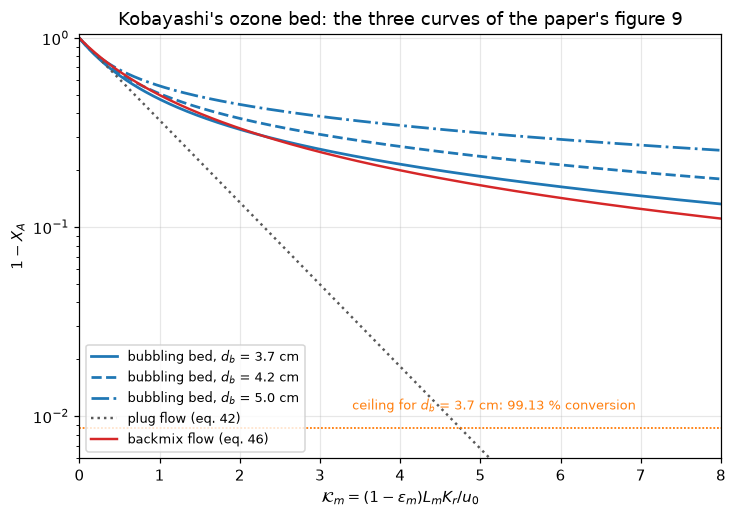

In [6]:
Km = np.linspace(1e-3, 8.0, 400)
fig, ax = plt.subplots(figsize=(6.8, 4.8))
for db, style in ((3.7, "-"), (4.2, "--"), (5.0, "-.")):
    h = hydrodynamics(**{**C, "db": db})
    ax.semilogy(Km, np.exp(-Kf_closed(Km, h)), style, color="C0", lw=1.8,
                label=f"bubbling bed, $d_b$ = {db} cm")
ax.semilogy(Km, np.exp(-Km), ":", color="0.35", lw=1.6, label="plug flow (eq. 42)")
ax.semilogy(Km, 1.0 / (1.0 + Km), color="C3", lw=1.6, label="backmix flow (eq. 46)")
ceil37 = ceiling_Kf(hC)
ax.axhline(np.exp(-ceil37), color="C1", lw=1.2, ls=(0, (1, 1)))
ax.text(3.4, np.exp(-ceil37) * 1.25, f"ceiling for $d_b$ = 3.7 cm: "
        f"{100 * (1 - np.exp(-ceil37)):.2f} % conversion", color="C1", fontsize=8.5)
ax.set_xlim(0, 8); ax.set_ylim(0.006, 1.05)
ax.set_xlabel(r"$\mathcal{K}_m = (1-\varepsilon_m)L_m K_r/u_0$")
ax.set_ylabel(r"$1-X_A$")
ax.set_title("Kobayashi's ozone bed: the three curves of the paper's figure 9")
ax.legend(fontsize=8.5, loc="lower left")
fig.tight_layout(); plt.show()

The three solid curves are the ones printed on the paper's figure 9, at the
bubble sizes the authors fitted. Two features are worth naming.

**The bed falls below backmix flow.** Not asymptotically: it crosses. Beyond a
finite $\mathcal{K}_m$ a bubbling bed converts less than a perfectly stirred
tank of the same catalyst, which no dispersion model can reproduce at all.

**And it flattens.** As $K_r \to \infty$ equation 49's bracket collapses to
$K_{bc}/K_r$, and $\mathcal{K}_f \to K_{bc}L_f/u_b$, a **finite ceiling** that
does not contain the rate constant. Reaction stops being the limiting step and
bubble-to-cloud interchange takes over completely.

Since the ceiling is finite and $1/(1+\mathcal{K}_m)$ falls without bound, every
bed crosses backmix flow somewhere, though for the smaller bubbles only at a
$\mathcal{K}_m$ two to five orders of magnitude beyond the 8 of figure 9, where
equation 54 sits at its ceiling and the model is no longer a description of any
bed. The crossing is a root of
$\ln(1+\mathcal{K}_m) - \mathcal{K}_f$, located by `pymrm.checks.find_roots` on
a logarithmic scan of $10^{-6}$ to $10^{9}$, which must find exactly one.

In [7]:
DB_LIST = (2.0, 3.0, 3.7, 4.2, 5.0, 7.0)
print("Where the bubbling bed becomes worse than a stirred tank, and where it stops:")
print(f"  {'d_b [cm]':>9}{'crosses backmix at K_m':>25}{'ceiling K_f':>14}{'max conversion':>17}")
cross, ceil_conv = {}, {}
for db in DB_LIST:
    h = hydrodynamics(**{**C, "db": db})
    cross[db] = backmix_crossing(h)
    ceil_conv[db] = 1 - np.exp(-ceiling_Kf(h))
    print(f"  {db:9.1f}{cross[db]:25.4g}{ceiling_Kf(h):14.3f}{100 * ceil_conv[db]:16.4f} %")
print(f"\nAt the fitted d_b = 3.7 cm this bed cannot exceed {100 * ceil_conv[3.7]:.2f} % "
      "conversion, however active the catalyst.")
claims.value("ceiling_conversion_db37", ceil_conv[3.7], rtol=1e-6)
claims.value("ceiling_conversion_db50", ceil_conv[5.0], rtol=1e-6)
claims.value("ceiling_conversion_db70", ceil_conv[7.0], rtol=1e-6)
claims.value("backmix_crossing_db37", cross[3.7], rtol=1e-6,
             note="find_roots, xtol 1e-12")
claims.value("backmix_crossing_db30", cross[3.0], rtol=1e-6, note="find_roots, xtol 1e-12")
claims.value("backmix_crossing_db20", cross[2.0], rtol=1e-6, note="find_roots, xtol 1e-12")
print(f"The crossings for d_b = 2 and 3 cm, at K_m = {cross[2.0]:.2g} and {cross[3.0]:.1f}, are "
      f"equation 54 at its ceiling: {cross[2.0] / 8:.0f} and {cross[3.0] / 8:.0f} times the K_m = 8 "
      "at the edge of figure 9, and outside any physical range. They state a property of "
      "equation 54, not a prediction for a bed.")


def crossings_found(hi):
    """How many of the d_b values cross backmix flow below K_m = hi."""
    return sum(backmix_crossing(hydrodynamics(**{**C, "db": db}), hi=hi) is not None
               for db in DB_LIST)


claims.exact("backmix_crossings_found", crossings_found(1e9),
             note=f"of the {len(DB_LIST)} bubble sizes in the table")
print(f"{crossings_found(1e9)} of {len(DB_LIST)} bubble sizes cross backmix flow below K_m = 1e9.")

Where the bubbling bed becomes worse than a stirred tank, and where it stops:
   d_b [cm]   crosses backmix at K_m   ceiling K_f   max conversion
        2.0                4.417e+05        12.999         99.9998 %
        3.0                    634.6         6.688         99.8755 %
        3.7                    2.267         4.748         99.1328 %
        4.2                   0.8137         3.861         97.8948 %
        5.0                   0.3525         2.906         94.5310 %
        7.0                   0.1238         1.682         81.3995 %

At the fitted d_b = 3.7 cm this bed cannot exceed 99.13 % conversion, however active the catalyst.
The crossings for d_b = 2 and 3 cm, at K_m = 4.4e+05 and 634.6, are equation 54 at its ceiling: 55207 and 79 times the K_m = 8 at the edge of figure 9, and outside any physical range. They state a property of equation 54, not a prediction for a bed.
6 of 6 bubble sizes cross backmix flow below K_m = 1e9.


The ceiling has a closed form, and the interesting thing about it is what it
does *not* contain. Substituting equation 4 for $L_f$ and $(1-\delta)u_b = u_{br}$:

$$
\mathcal{K}_f^{\max} = \frac{K_{bc}L_f}{u_b}
= \frac{K_{bc}(d_b)\,(1-\varepsilon_m)L_m}{(1-\varepsilon_{mf})\,u_{br}(d_b)}
$$

Both $K_{bc}$ and $u_{br}$ depend on the bubble size and not on the gas
velocity, so **at a fixed bubble size the ceiling is independent of $u_0$**.
Push more gas through a bed and, at fixed bubble size, the best conversion it can
ever reach does not move.

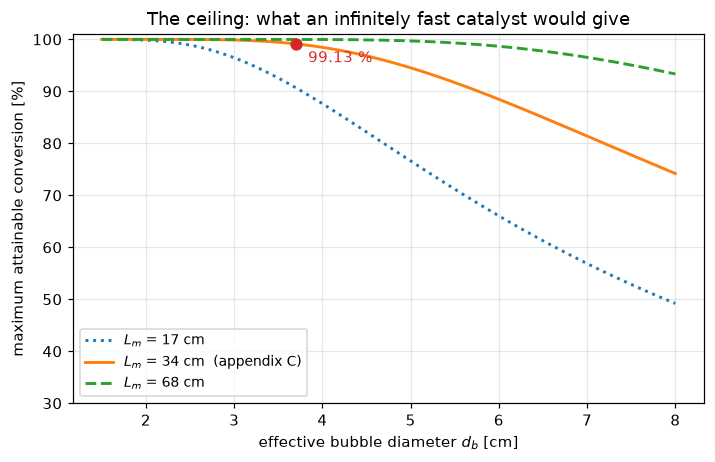

ceiling K_f at u_0 = 5, 13.2, 40, 200 cm/s: 4.7476911297, 4.7476911297, 4.7476911297, 4.7476911297
relative spread below 1e-14 (here 3.7e-16): an algebraic identity, since
K_bc(d_b) and u_br(d_b) contain no u_0 for any coefficient values.


In [8]:
db_grid = np.linspace(1.5, 8.0, 300)
fig, ax = plt.subplots(figsize=(6.6, 4.3))
for Lm, style in ((17.0, ":"), (34.0, "-"), (68.0, "--")):
    ceil = np.array([ceiling_Kf(hydrodynamics(**{**C, "db": db, "Lm": Lm})) for db in db_grid])
    ax.plot(db_grid, 100 * (1 - np.exp(-ceil)), style, lw=1.9,
            label=f"$L_m$ = {Lm:.0f} cm" + ("  (appendix C)" if Lm == 34 else ""))
ax.plot(C["db"], 100 * ceil_conv[3.7], "o", ms=7, color="C3")
ax.annotate(f"{100 * ceil_conv[3.7]:.2f} %", (C["db"], 100 * ceil_conv[3.7]),
            textcoords="offset points", xytext=(8, -12), color="C3")
ax.set_xlabel(r"effective bubble diameter $d_b$ [cm]")
ax.set_ylabel("maximum attainable conversion [%]")
ax.set_title("The ceiling: what an infinitely fast catalyst would give")
ax.set_ylim(30, 101); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

U0_SET = (5.0, 13.2, 40.0, 200.0)


def ceiling_u0_spread(hydro=hydrodynamics):
    """Relative spread of the ceiling K_f over U0_SET, at fixed d_b."""
    cs = np.array([ceiling_Kf(hydro(**{**C, "u0": u0})) for u0 in U0_SET])
    return float(np.ptp(cs) / np.mean(cs)), cs


spread, cs = ceiling_u0_spread()
print("ceiling K_f at u_0 =", ", ".join(f"{u:g}" for u in U0_SET), "cm/s:",
      ", ".join(f"{c:.10f}" for c in cs))
print(f"relative spread below 1e-14 (here {spread:.1e}): an algebraic identity, since")
print("K_bc(d_b) and u_br(d_b) contain no u_0 for any coefficient values.")
claims.bound("ceiling_u0_spread", spread, max=1e-14, basis="identity")

This is a statement about equation 49 and about this bed's $L_m$,
$\varepsilon_m$, $\varepsilon_{mf}$ and $u_{mf}$, not a universal chart. What it
shows is that the ceiling is governed by $d_b$ and by how deep the bed is.
Doubling the bubble size from 3 to 6 cm costs more conversion than any catalyst
can give back, and the only lever left is bed depth, which enters linearly in
$\mathcal{K}_f^{\max}$ and therefore only logarithmically in the conversion.

The caveat is the one the paper spends its conclusion on: real bubbles grow with
gas velocity, so $u_0$ does move the ceiling, through $d_b$, which the model
does not predict.

### The distributed model: what the frozen cloud and emulsion leave out

The table compares equation 54 with the distributed model, both emulsion
closures, at the $\mathcal{K}_m$ of the paper's figure 9. The extended values are
the exact eigenmode solution; the pymrm solve on 1600 cells is printed beside
them and its error is measured in the Validation section.

In [9]:
N_REP = 1600
bed_bal = BubblingBed(hC, N_REP)
bed_pap = BubblingBed(hC, N_REP, ve_mode="paper")
change = {"balance": [], "paper": []}
print(f"  {'K_m':>5}{'1-X eq. 54':>12}{'exact':>10}{'pymrm':>10}{'change':>9}"
      f"   |{'exact':>9}{'pymrm':>10}{'change':>9}")
print(f"  {'':5}{'':12}{'v_e from overall balance':>29}   |{'v_e from eqs. 5 and 7':>28}")
for km in KM_LIST:
    base = np.exp(-Kf_closed(km, hC))
    line = f"  {km:5.1f}{base:12.4f}"
    for mode, bed in (("balance", bed_bal), ("paper", bed_pap)):
        ex = extended_exact(km, hC, mode)
        assert ex["imag"] < 1e-12
        change[mode].append(ex["c_exit"] / base - 1)
        line += ("   |" if mode == "paper" else "") + \
            f"{ex['c_exit']:10.4f}{bed.solve(km).c_exit:10.4f}{100 * change[mode][-1]:8.1f} %"
    print(line)
ch_b, ch_p = np.array(change["balance"]), np.array(change["paper"])
print(f"\nwith the overall balance the fraction unconverted rises by {100 * ch_b.min():.1f} to "
      f"{100 * ch_b.max():.1f} %; with eqs. 5 and 7 by {100 * ch_p.min():.2f} to {100 * ch_p.max():.1f} %")
claims.value("extension_min_change", ch_b.min(), rtol=1e-6, note="exact eigenmode route")
claims.value("extension_max_change", ch_b.max(), rtol=1e-6, note="exact eigenmode route")
claims.value("extension_paper_ve_min_change", ch_p.min(), rtol=1e-6)
claims.value("extension_paper_ve_max_change", ch_p.max(), rtol=1e-6)
IK4, IK8 = list(KM_LIST).index(4.0), list(KM_LIST).index(8.0)
claims.value("extension_exact_change_Km4", ch_b[IK4], rtol=1e-6)
claims.value("extension_exact_change_Km8", ch_b[IK8], rtol=1e-6)
claims.value("extension_paper_exact_change_Km8", ch_p[IK8], rtol=1e-6)
KM_PY = {"balance": bed_bal, "paper": bed_pap}


def pymrm_change(mode, km, **kw):
    """Change of 1 - X from the pymrm solve on N_REP cells (what the earlier page printed)."""
    return KM_PY[mode].solve(km, **kw).c_exit / np.exp(-Kf_closed(km, hC)) - 1


print(f"on {N_REP} cells the pymrm exit gives {100 * pymrm_change('balance', 4.0):.1f} % and "
      f"{100 * pymrm_change('balance', 8.0):.1f} % at K_m = 4 and 8 (overall balance), "
      f"{100 * pymrm_change('paper', 8.0):.1f} % at K_m = 8 (eqs. 5 and 7); the exact "
      f"values are {100 * ch_b[IK4]:.1f} %, {100 * ch_b[IK8]:.1f} % and {100 * ch_p[IK8]:.1f} %")
claims.value("extension_pymrm_change_Km4_n1600", pymrm_change("balance", 4.0), rtol=1e-4)
claims.value("extension_pymrm_change_Km8_n1600", pymrm_change("balance", 8.0), rtol=1e-4)
claims.value("extension_paper_pymrm_change_Km8_n1600", pymrm_change("paper", 8.0), rtol=1e-4)
cond = max(extended_exact(km, hC, m)["cond"] for km in KM_LIST for m in ("balance", "paper"))
print(f"condition number of the 5 x 5 eigenmode system below 1e3 (here {cond:.0f})")
claims.bound("exact_route_condition", cond, max=1e3, basis="chosen",
             note="well below 1/eps: the scaled modes keep the route exact to round-off")

    K_m  1-X eq. 54     exact     pymrm   change   |    exact     pymrm   change
                        v_e from overall balance   |       v_e from eqs. 5 and 7
    0.5      0.6347    0.6804    0.6804     7.2 %   |    0.6363    0.6363     0.3 %
    1.0      0.4754    0.5282    0.5283    11.1 %   |    0.4994    0.4995     5.0 %


    2.0      0.3292    0.3763    0.3764    14.3 %   |    0.3597    0.3598     9.3 %
    4.0      0.2155    0.2470    0.2471    14.6 %   |    0.2388    0.2389    10.8 %
    8.0      0.1327    0.1468    0.1469    10.6 %   |    0.1435    0.1436     8.1 %

with the overall balance the fraction unconverted rises by 7.2 to 14.6 %; with eqs. 5 and 7 by 0.25 to 10.8 %
on 1600 cells the pymrm exit gives 14.7 % and 10.7 % at K_m = 4 and 8 (overall balance), 8.2 % at K_m = 8 (eqs. 5 and 7); the exact values are 14.6 %, 10.6 % and 8.1 %
condition number of the 5 x 5 eigenmode system below 1e3 (here 28)


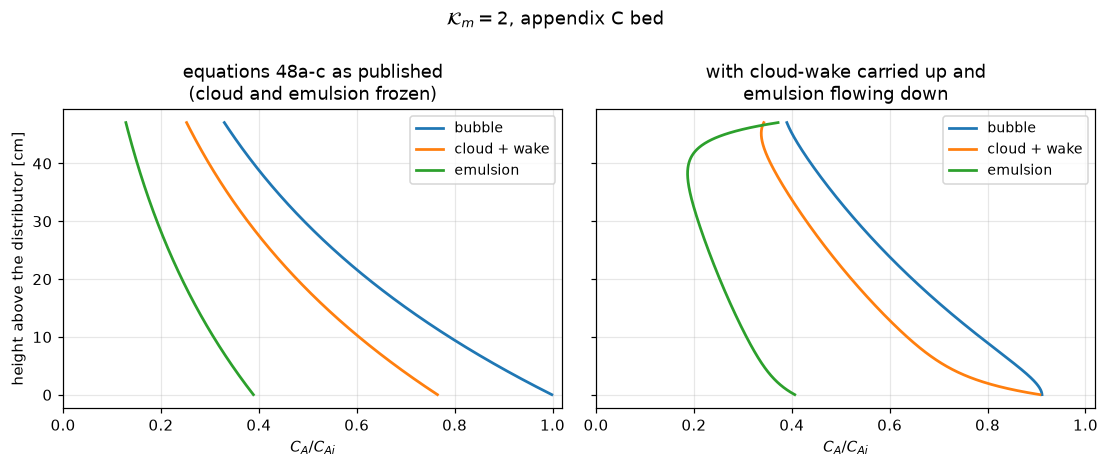

Feed mixed with recirculated emulsion gas at the bottom: C_in/C_Ai = 0.9112 (exact 0.9114)


In [10]:
# What the profiles look like once the regions can carry gas.
r = BubblingBed(hC, 800).solve(2.0)
r0 = BubblingBed(hC, 800, convect=False).solve(2.0)
fig, ax = plt.subplots(1, 2, figsize=(10.2, 4.2), sharey=True)
labels = ("bubble", "cloud + wake", "emulsion")
for k in range(3):
    ax[0].plot(r0.C[:, k], r0.bed.x_c, lw=1.8, label=labels[k])
    ax[1].plot(r.C[:, k], r.bed.x_c, lw=1.8, label=labels[k])
ax[0].set_title("equations 48a-c as published\n(cloud and emulsion frozen)")
ax[1].set_title("with cloud-wake carried up and\nemulsion flowing down")
for a in ax:
    a.set_xlabel(r"$C_A/C_{Ai}$"); a.set_xlim(0, 1.02); a.legend(fontsize=9)
ax[0].set_ylabel("height above the distributor [cm]")
fig.suptitle(r"$\mathcal{K}_m = 2$, appendix C bed", y=1.0)
fig.tight_layout(); plt.show()
print(f"Feed mixed with recirculated emulsion gas at the bottom: C_in/C_Ai = {r.c_in:.4f} "
      f"(exact {extended_exact(2.0, hC)['c_in']:.4f})")

**Can the fitted bubble size absorb the extension?** For each $\mathcal{K}_m$, the
bubble size at which equation 54 gives the extended model's exit (a root on
$3 \le d_b \le 6$ cm, which must be unique):

In [11]:
def one_root(f, lo=0.05, hi=50.0, strict=True):
    """The single root of f on [lo, hi]; raises (or, not strict, gives nan) otherwise."""
    res = find_roots(f, lo, hi, n_scan=200, log=True)
    if len(res["roots"]) != 1 or res["failed"]:
        if strict:
            raise RuntimeError(res["message"])
        print(f"   not one root: {res['message']}")
        return np.nan
    return res["roots"][0]


def equivalent_db(coef=None, strict=True):
    """Per K_m, the d_b at which eq. 54 equals the extended exit at d_b = 3.7 cm."""
    h = hydrodynamics(**C, coef=coef)
    out = []
    for km in KM_LIST:
        try:
            c_ext = extended_exact(km, h)["c_exit"]
            if not c_ext > 0:
                raise ValueError(f"extended exit {c_ext:.3g} is not a concentration")
            target = np.log(c_ext)
        except ValueError:
            if strict:
                raise
            out.append(np.nan)
            continue
        out.append(one_root(lambda d: Kf_closed(km, hydrodynamics(**{**C, "db": d}, coef=coef))
                            + target, 3.0, 6.0, strict=strict))
    return np.array(out)


EQ_DB = equivalent_db()
for km, d in zip(KM_LIST, EQ_DB):
    print(f"   K_m = {km:3.1f}: equation 54 needs d_b = {d:.3f} cm")
print(f"   one bubble size absorbs the extension only at one K_m: {EQ_DB.min():.2f} to "
      f"{EQ_DB.max():.2f} cm over figure 9's range")
claims.value("equivalent_db_min", EQ_DB.min(), rtol=1e-6)
claims.value("equivalent_db_max", EQ_DB.max(), rtol=1e-6)
claims.value("equivalent_db_Km2", EQ_DB[list(KM_LIST).index(2.0)], rtol=1e-6)

   K_m = 0.5: equation 54 needs d_b = 5.002 cm
   K_m = 1.0: equation 54 needs d_b = 4.503 cm
   K_m = 2.0: equation 54 needs d_b = 4.200 cm
   K_m = 4.0: equation 54 needs d_b = 4.002 cm
   K_m = 8.0: equation 54 needs d_b = 3.851 cm
   one bubble size absorbs the extension only at one K_m: 3.85 to 5.00 cm over figure 9's range


## Validation

The checks are **not of equal weight**, and the break table at the end of this
section measures it: every claim is re-evaluated with one defect injected.

**The appendix comparisons have power.** They are the only checks on this page
that can see a wrong *number*: each takes the coefficients transcribed out of
equations 10, 12 and 51 and puts them against arithmetic the authors printed.

**The identities do not.** The $K_r \to 0$ limit, the reactant balance of the
distributed model and the ceiling's $u_0$-independence hold for any values of the
printed coefficients, so they catch a wrong *formula* and never a wrong *number*.
They are kept because a wrong formula is a real error class, each with the
formula defect it catches.

**The distributed model has its own ladder** against the exact eigenmode
solution, on the branch the extension numbers are reported on.

### 1. Appendix C, every printed intermediate

In [12]:
PAIRS_C = (("u_br", "ubr"), ("u_b", "ub"), ("delta", "delta"), ("K_bc", "Kbc"),
           ("K_ce", "Kce"), ("gamma_c", "gc"), ("gamma_e", "ge"))


def appendix_C_devs(coef=None):
    """Relative deviation of each recomputed appendix C intermediate."""
    h = hydrodynamics(**C, coef=coef)
    got = {s: h[k] for s, k in PAIRS_C} | {"Kr_per_Km": Kr_of_Km(1.0, h)}
    return {s: abs(g - printed("C", s)) / abs(printed("C", s)) for s, g in got.items()}, got


devC, gotC = appendix_C_devs()
print(f"   {'quantity':>10}{'printed':>12}{'recomputed':>14}{'deviation':>12}")
for s in devC:
    print(f"   {s:>10}{printed('C', s):12.4g}{gotC[s]:14.6g}{100 * devC[s]:11.2f} %")
print(f"   worst deviation {100 * max(devC.values()):.2f} %, over {len(devC)} numbers, nothing fitted")
claims.value("appendixC_max_dev", max(devC.values()), rtol=1e-4)

     quantity     printed    recomputed   deviation
         u_br        42.8       42.8138       0.03 %
          u_b        53.9       53.9138       0.03 %
        delta       0.206      0.205884       0.06 %
         K_bc        5.44       5.43494       0.09 %
         K_ce        2.23       2.23397       0.18 %
      gamma_c         0.4      0.398154       0.46 %
      gamma_e        1.53       1.53039       0.03 %
    Kr_per_Km       0.706      0.705882       0.02 %
   worst deviation 0.46 %, over 8 numbers, nothing fitted


### 2. Appendix A: the same flow model, for gas–solid mass transfer

In [13]:
def appendix_A_dev(coef=None):
    got = appendix_A(A, coef)
    return max(abs(v - printed("A", s)) / abs(printed("A", s)) for s, v in got.items()), got


devA, gotA = appendix_A_dev()
print(f"   {'quantity':>22}{'printed':>12}{'recomputed':>14}{'deviation':>12}")
for s, val in gotA.items():
    want = printed("A", s)
    print(f"   {s:>22}{want:12.4g}{val:14.6g}{100 * abs(val - want) / abs(want):11.2f} %")
print(f"   (Sh)_over-all = {gotA['Sh_slope_Re']:.4f} Re - {-gotA['Sh_intercept']:.4f}"
      f"   against the printed 0.045 Re - 0.0101")
claims.value("appendixA_max_dev", devA, rtol=1e-4)

                 quantity     printed    recomputed   deviation
                     Re_t        7.54       7.52578       0.19 %
                Sh_star_t         4.2       4.20069       0.02 %
                     K_bc        46.5       46.5552       0.12 %
              ub_minus_u0          12       11.9579       0.35 %
    one_minus_ef_times_ub         6.6       6.58395       0.24 %
                Re_per_u0       0.184      0.183556       0.24 %
              Sh_slope_u0     0.00829    0.00830733       0.21 %
             Sh_intercept     -0.0101    -0.0100519       0.48 %
              Sh_slope_Re       0.045     0.0452579       0.57 %
   (Sh)_over-all = 0.0453 Re - 0.0101   against the printed 0.045 Re - 0.0101


### 3. Appendix B: the same flow model again, for gas–solid heat transfer

In [14]:
def appendix_B_line(b, x):
    """(Nu)_apparent = intercept + slope Re for (1 - eps_f)(u_0 + 5.8) = x."""
    return b["brack"] / x * b["ub_minus_u0"], b["brack"] / x / b["Re_per_u0"]


def appendix_B_dev(coef=None):
    b = appendix_B(B, coef)
    devs = [abs(b[s] - printed("B", s)) / abs(printed("B", s))
            for s in ("Re_t", "Nu_star_t", "H_bc", "ub_minus_u0", "Re_per_u0")]
    inter, slope = appendix_B_line(b, printed("B", "one_minus_ef_times_ub"))
    devs += [abs(slope / printed("B", "Nu_slope_Re") - 1),
             abs(inter / printed("B", "Nu_intercept") - 1)]
    x_pr = printed("B", "one_minus_ef_times_ub")
    return max(devs), b, 1 - x_pr / b["ubr"], x_pr / b["one_minus_ef_own"] - 1


devB, b, emf_implied, own_shift = appendix_B_dev()
x_pr = printed("B", "one_minus_ef_times_ub")
print(f"   {'quantity':>22}{'printed':>12}{'recomputed':>14}{'deviation':>12}")
for s in ("Re_t", "Nu_star_t", "H_bc", "ub_minus_u0", "Re_per_u0"):
    want = printed("B", s)
    print(f"   {s:>22}{want:12.4g}{b[s]:14.6g}{100 * abs(b[s] - want) / abs(want):11.2f} %")
for tag, x in ((f"as printed, {x_pr:.2f}", x_pr),
               ("from its own eps_mf = 0.50", b["one_minus_ef_own"])):
    inter, slope = appendix_B_line(b, x)
    print(f"   (Nu)_apparent = {inter:.4f} + {slope:.4f} Re   [{tag}]")
print(f"   the printed answer is        {printed('B', 'Nu_intercept'):.4f} + "
      f"{printed('B', 'Nu_slope_Re'):.4f} Re")
print(f"\n   Only the printed {x_pr:.2f} reproduces the printed answer, so it is what the")
print(f"   authors used. Their stated eps_mf = 0.50 gives {b['one_minus_ef_own']:.2f}, which would")
print(f"   move the line by {100 * own_shift:.1f} %. {x_pr:.2f} corresponds to "
      f"eps_mf = {emf_implied:.3f}. Recorded, not repaired.")
claims.value("appendixB_max_dev", devB, rtol=1e-4)
claims.value("appendixB_emf_implied", emf_implied, rtol=1e-4)
claims.value("appendixB_own_emf_shift", own_shift, rtol=1e-4)

                 quantity     printed    recomputed   deviation
                     Re_t        20.3        20.296       0.02 %
                Nu_star_t        4.39       4.38858       0.03 %
                     H_bc       0.036     0.0358451       0.43 %
              ub_minus_u0         5.8       5.73866       1.06 %
                Re_per_u0       0.236         0.236       0.00 %
   (Nu)_apparent = 0.0688 + 0.0508 Re   [as printed, 8.70]
   (Nu)_apparent = 0.0760 + 0.0561 Re   [from its own eps_mf = 0.50]
   the printed answer is        0.0700 + 0.0510 Re

   Only the printed 8.70 reproduces the printed answer, so it is what the
   authors used. Their stated eps_mf = 0.50 gives 7.87, which would
   move the line by 10.6 %. 8.70 corresponds to eps_mf = 0.447. Recorded, not repaired.


### 4. The frozen distributed solve against equation 54

With $v_c = v_e = 0$ the cloud and emulsion rows are algebraic and the bubble row
is first-order upwind with an exact inlet value and an outflow outlet: the
discrete exit is then exactly the backward-Euler product
$(1+\mathcal{K}_f/n)^{-n}$, an identity of the scheme. Its error against
$e^{-\mathcal{K}_f}$ is first order, and a first-order Richardson step removes
it. This branch never enters the recirculation loop, so it licenses the operator
assembly and nothing about the extension numbers.

In [15]:
NS_FROZEN = (200, 400, 800, 1600)
KM_FROZEN = (0.5, 2.0, 8.0)


def frozen_metrics(outlet="outflow", kbc_asym=1.0, cap=None):
    """Frozen ladder: identity gap, errors against eq. 54, orders, Richardson."""
    gap, rows = 0.0, []
    for km in KM_FROZEN:
        base = np.exp(-Kf_closed(km, hC))
        cs = []
        for n in NS_FROZEN:
            m = n if cap is None else min(n, cap)
            c = BubblingBed(hC, m, convect=False, outlet=outlet).solve(km, kbc_asym).c_exit
            gap = max(gap, abs(c / (1 + Kf_closed(km, hC) / m) ** -m - 1))
            cs.append(c)
        err = np.abs(np.array(cs) / base - 1)
        rows.append((km, base, err, np.log2(err[:-1] / err[1:]),
                     abs((2 * cs[-1] - cs[-2]) / base - 1),
                     abs(cs[-1] - cs[-2]) / (NS_FROZEN[-1] * EPS)))
    return gap, rows


gap_be, rows_fr = frozen_metrics()
print(f"   {'K_m':>5}{'eq. 54':>10}" + "".join(f"{'n=' + str(n):>11}" for n in NS_FROZEN)
      + f"{'orders':>20}{'Richardson':>12}")
for km, base, err, orders, rich, _fl in rows_fr:
    print(f"   {km:5.1f}{base:10.5f}" + "".join(f"{e:11.2e}" for e in err)
          + "  " + " ".join(f"{o:.3f}" for o in orders) + f"{rich:12.1e}")
orders_fr = np.concatenate([r[3] for r in rows_fr])
print(f"   observed orders from {orders_fr.min():.3f} to {orders_fr.max():.3f}, within 0.02 of 1; "
      f"exit equals (1 + K_f/n)^-n to below 1e-11 (here {gap_be:.1e})")
fl_fr = min(r[5] for r in rows_fr)
print(f"   finest difference / (n eps): {fl_fr:.1e}, above 1e3")
claims.bound("frozen_vs_backward_euler", gap_be, max=1e-11, basis="identity")
claims.value("distributed_vs_eq54_n1600", max(r[2][-1] for r in rows_fr), rtol=1e-3)
claims.value("distributed_vs_eq54_richardson", max(r[4] for r in rows_fr), rtol=1e-3)
claims.bound("frozen_order_worst_dev", np.max(np.abs(orders_fr - 1)), max=0.02, basis="theory",
             note="first-order upwind; every consecutive pair at every K_m")
claims.bound("frozen_finest_over_roundoff", fl_fr, min=1e3, basis="theory")

     K_m    eq. 54      n=200      n=400      n=800     n=1600              orders  Richardson
     0.5   0.63471   5.16e-04   2.58e-04   1.29e-04   6.46e-05  0.999 1.000 1.000     2.0e-08
     2.0   0.32922   3.08e-03   1.54e-03   7.71e-04   3.86e-04  0.998 0.999 1.000     2.1e-07
     8.0   0.13271   1.02e-02   5.09e-03   2.55e-03   1.27e-03  0.999 0.999 1.000     5.2e-07
   observed orders from 0.998 to 1.000, within 0.02 of 1; exit equals (1 + K_f/n)^-n to below 1e-11 (here 1.5e-13)
   finest difference / (n eps): 1.2e+08, above 1e3


### 5. The slow-reaction limit (an identity)

Equation 57 asserts $\mathcal{K}_f = \mathcal{K}_m$ for slow reaction. As
$K_r \to 0$ the bracket of equation 49 collapses to
$\gamma_b+\gamma_c+\gamma_e$, which equation 15 *defines* as
$(1-\varepsilon_{mf})(1-\delta)/\delta$, and with $(1-\delta)u_b = u_{br}$ every
coefficient cancels except $u_0/(u_0-u_{mf})$, because the exit stream is bubble
gas only. `Kf_over_Km` is evaluated at $\mathcal{K}_m = 0$ exactly.

In [16]:
def eq57_dev(h):
    """Deviation of lim K_f/K_m (K_m -> 0) from u_0/(u_0 - u_mf)."""
    lim = h["u0"] / (h["u0"] - h["umf"])
    return abs(Kf_over_Km(0.0, h) / lim - 1)


print(f"   lim K_f/K_m = {Kf_over_Km(0.0, hC):.6f}, u_0/(u_0 - u_mf) = "
      f"{C['u0'] / (C['u0'] - C['umf']):.6f}; deviation below 1e-14 (here {eq57_dev(hC):.1e})")
print(f"   so equation 57's K_f = K_m is {100 * (Kf_over_Km(0.0, hC) - 1):.1f} % optimistic "
      "for this bed; it is exact only as u_0/u_mf -> infinity.")
claims.bound("eq57_limit_dev", eq57_dev(hC), max=1e-14, basis="identity")
claims.value("eq57_optimism", Kf_over_Km(0.0, hC) - 1, rtol=1e-6)

   lim K_f/K_m = 1.189189, u_0/(u_0 - u_mf) = 1.189189; deviation below 1e-14 (here 2.2e-16)
   so equation 57's K_f = K_m is 18.9 % optimistic for this bed; it is exact only as u_0/u_mf -> infinity.


### 6. The reactant balance of the distributed model (an identity)

The reaction integrated over the bed must equal what the gas loses between feed
and exit, $u_0(1-C_{\rm exit})$. With the outlet face values the operator
transports, the discrete fluxes telescope, the exchange block has column sums
$-\delta\gamma_k K_r$ (the $K_{bc}$ and $K_{ce}$ terms cancel pairwise), and the
velocities sum to $u_0$ by the closure, so the balance closes to round-off on
every grid. It is checked on every $\mathcal{K}_m$ of the table and every rung of
the ladder below.

In [17]:
NS_EXT = (200, 400, 800, 1600, 3200, 6400)


def worst_balance(ns=NS_EXT, kms=KM_LIST, **bed_kw):
    """Largest |mass_balance_dev| over the grids and K_m."""
    solve_kw = {k: bed_kw.pop(k) for k in ("kbc_asym",) if k in bed_kw}
    return max(abs(BubblingBed(hC, n, **bed_kw).solve(km, **solve_kw).mass_balance_dev())
               for n in ns for km in kms)


mb = worst_balance()
s2 = BubblingBed(hC, N_REP).solve(2.0)
print(f"   K_m = 2, n = {N_REP}: consumed {s2.consumed():.8f}, u_0 (1 - C_exit) "
      f"{C['u0'] * (1 - s2.c_exit):.8f}")
print(f"   worst relative closure over {len(NS_EXT)} grids and {len(KM_LIST)} K_m: "
      f"below 1e-10 (here {mb:.1e})")
claims.bound("mass_balance_dev", mb, max=1e-10, basis="identity")


def zero_gradient_gap(n=2000, km=2.0, **kw):
    """Signed reactant-balance gap with zero-gradient outlets (the construction this page retired)."""
    kb = {k: kw.pop(k) for k in ("kbc_asym",) if k in kw}
    return BubblingBed(hC, n, outlet="zero_gradient", **kw).solve(km, **kb).mass_balance_dev()


zg = zero_gradient_gap()
print(f"   zero-gradient outlets with the exit read from the last cells, K_m = 2, n = 2000: "
      f"gap {zg:.4e}, against {abs(BubblingBed(hC, 2000).solve(2.0).mass_balance_dev()):.1e} "
      "with outflow outlets")
claims.value("mass_balance_zero_gradient_n2000", zg, rtol=1e-3,
             note="signed gap of the retired zero-gradient construction")

   K_m = 2, n = 1600: consumed 8.23190923, u_0 (1 - C_exit) 8.23190923
   worst relative closure over 6 grids and 5 K_m: below 1e-10 (here 1.7e-12)
   zero-gradient outlets with the exit read from the last cells, K_m = 2, n = 2000: gap -8.1061e-06, against 1.3e-14 with outflow outlets


### 7. The distributed model against its exact solution

The extension numbers are taken on the `convect=True` branch, so that branch gets
its own ladder: the exit concentration on six nested grids at every
$\mathcal{K}_m$ of the table, the observed order from
`pymrm.checks.observed_orders` (no exact solution needed), and the error against
the eigenmode solution. The finest difference is compared with a round-off floor
$n\,\varepsilon$, so that the order is not fitted to noise.

In [18]:
def ext_ladder(ns=NS_EXT, cap=None, **solve_kw):
    """Per K_m: observed_orders result and the exact exit, on the balance closure."""
    beds = {n: BubblingBed(hC, n if cap is None else min(n, cap)) for n in ns}
    out = []
    for km in KM_LIST:
        oo = observed_orders(lambda n: beds[n].solve(km, **solve_kw).c_exit, ns)
        out.append((km, oo, extended_exact(km, hC)["c_exit"]))
    return out


def ext_metrics(lad, ns=NS_EXT):
    orders = np.concatenate([oo["orders"] for _, oo, _ in lad])
    err = [abs(oo["values"][ns.index(N_REP)] / ex - 1) for _, oo, ex in lad]
    rich = [abs(oo["extrapolated"] / ex - 1) for _, oo, ex in lad]
    finest = min(abs(oo["values"][-1] - oo["values"][-2]) for _, oo, _ in lad)
    return orders, max(err), max(rich), finest / (ns[-1] * EPS)


LAD = ext_ladder()
print(f"   {'K_m':>5}{'exact':>14}" + "".join(f"{'n=' + str(n):>10}" for n in NS_EXT[::2])
      + f"{'orders':>34}")
for km, oo, ex in LAD:
    errs = np.abs(np.array(oo["values"]) / ex - 1)
    print(f"   {km:5.1f}{ex:14.10f}" + "".join(f"{e:10.2e}" for e in errs[::2]) + "  "
          + " ".join(f"{o:.4f}" for o in oo["orders"]))
ord_e, err_e, rich_e, fl_e = ext_metrics(LAD)
print(f"   observed orders {ord_e.min():.4f} to {ord_e.max():.4f}, within 0.02 of 1; at n = {N_REP} the worst "
      f"error against the exact exit is {err_e:.2e}")
print(f"   Richardson limit of the finest triple against exact: {rich_e:.1e}; "
      f"finest difference / (n eps): {fl_e:.1e}")
claims.bound("extension_order_worst_dev", np.max(np.abs(ord_e - 1)), max=0.02, basis="theory",
             note="observed_orders, every triple at every K_m")
claims.value("extension_pymrm_vs_exact_n1600", err_e, rtol=1e-3)
claims.value("extension_richardson_vs_exact", rich_e, rtol=0.05)
claims.bound("extension_finest_over_roundoff", fl_e, min=1e3, basis="theory")

     K_m         exact     n=200     n=800    n=3200                            orders
     0.5  0.6804091040  2.32e-04  5.78e-05  1.44e-05  1.0048 1.0025 1.0013 1.0007
     1.0  0.5282386368  6.45e-04  1.61e-04  4.01e-05  1.0055 1.0029 1.0015 1.0008
     2.0  0.3762976687  1.56e-03  3.87e-04  9.68e-05  1.0063 1.0034 1.0017 1.0009
     4.0  0.2469840740  3.36e-03  8.35e-04  2.09e-04  1.0067 1.0036 1.0019 1.0010
     8.0  0.1468090188  6.74e-03  1.68e-03  4.19e-04  1.0064 1.0035 1.0019 1.0009
   observed orders 1.0007 to 1.0067, within 0.02 of 1; at n = 1600 the worst error against the exact exit is 8.38e-04
   Richardson limit of the finest triple against exact: 1.8e-07; finest difference / (n eps): 3.5e+06


### 8. Two claims the paper makes in passing

Both are stated without support, and both are cheap to test once the model runs.
Each limit is a root located by `find_roots`, which must find exactly one.

In [19]:
def gamma_b_change(km, coef=None):
    h0 = hydrodynamics(**C, coef=coef)
    h1 = hydrodynamics(**{**C, "gamma_b": 0.01}, coef=coef)
    return np.exp(-Kf_closed(km, h1)) / np.exp(-Kf_closed(km, h0)) - 1


def cloud_wake_change(km, coef=None):
    """Adding the cloud-wake gas (eqs. 48b, 48c) to the exit: relative change of 1 - X."""
    h = hydrodynamics(**C, coef=coef)
    Kr, Cb = Kr_of_Km(km, h), np.exp(-Kf_closed(km, h))
    ge_eff = h["Kce"] * h["ge"] * Kr / (h["Kce"] + h["ge"] * Kr)
    Cc = h["Kbc"] * Cb / (h["Kbc"] + h["gc"] * Kr + ge_eff)
    vb, vc = velocities(h)[:2]
    return (vb * Cb + vc * Cc) / (vb + vc) / Cb - 1


def passing_claims(coef=None, strict=True):
    gb = max(abs(gamma_b_change(km, coef)) for km in KM_LIST)
    cw = max(abs(cloud_wake_change(km, coef)) for km in KM_LIST)
    return (gb, one_root(lambda K: abs(gamma_b_change(K, coef)) - 0.01, strict=strict),
            cw, one_root(lambda K: abs(cloud_wake_change(K, coef)) - 0.10, strict=strict))


print("Claim 1 (appendix C): gamma_b anywhere in 0 to 0.01 changes the outlet")
print("concentration by less than 1 %.  Claim 2 (after eq. 53): adding the cloud-wake")
print("gas to the exit stream changes the fraction unconverted by 10 % at most.")
print(f"   {'K_m':>5}{'gamma_b 0 -> 0.01':>20}{'+ cloud-wake gas':>19}")
for km in KM_LIST:
    print(f"   {km:5.1f}{100 * gamma_b_change(km):19.2f} %{100 * cloud_wake_change(km):18.1f} %")
gb_w, gb_lim, cw_w, cw_lim = passing_claims()
print(f"   claim 1 holds up to K_m = {gb_lim:.2f}; at K_m = 8 the change is {100 * gb_w:.1f} %")
print(f"   claim 2 holds up to K_m = {cw_lim:.2f}; at K_m = 8 the change is {100 * cw_w:.1f} %")
claims.value("gamma_b_claim_worst", gb_w, rtol=1e-4)
claims.value("gamma_b_claim_Km_limit", gb_lim, rtol=1e-6)
claims.value("cloud_wake_claim_worst", cw_w, rtol=1e-4)
claims.value("cloud_wake_claim_Km_limit", cw_lim, rtol=1e-6)
cw_05 = cloud_wake_change(0.5)
print(f"   at K_m = 0.5 the cloud-wake gas alone changes the fraction unconverted by "
      f"{100 * cw_05:.1f} %, against {100 * ch_b.min():.1f} % for the whole extension")
claims.value("cloud_wake_change_Km05", cw_05, rtol=1e-4)

Claim 1 (appendix C): gamma_b anywhere in 0 to 0.01 changes the outlet
concentration by less than 1 %.  Claim 2 (after eq. 53): adding the cloud-wake
gas to the exit stream changes the fraction unconverted by 10 % at most.
     K_m   gamma_b 0 -> 0.01   + cloud-wake gas
     0.5              -0.14 %              -2.7 %
     1.0              -0.42 %              -4.5 %
     2.0              -1.04 %              -6.7 %
     4.0              -2.31 %              -9.2 %
     8.0              -4.75 %             -12.1 %
   claim 1 holds up to K_m = 1.94; at K_m = 8 the change is 4.7 %
   claim 2 holds up to K_m = 4.88; at K_m = 8 the change is 12.1 %
   at K_m = 0.5 the cloud-wake gas alone changes the fraction unconverted by -2.7 %, against 7.2 % for the whole extension


### The break table

**Transcription defects.** The model has four printed numerical coefficients, the
`0.711` of equation 51, the `4.5` and `5.85` of equation 10 and the `6.78` of
equation 12, and the error that happens when a number is read off a 1968 scan is
a transposed digit. Each is perturbed through the `coef` argument and every
closed-form claim recomputed. **Formula defects** are injected through an
argument or a modified parameter set: an exchange block that does not conserve
the reactant, the emulsion velocity of equations 5 and 7, zero-gradient outlets,
$\gamma_e$ off equation 15's closure, a spurious $u_0$ dependence in $K_{bc}$, a
backmix scan that stops at $\mathcal{K}_m = 50$, and a ladder whose finest rung is
not refined.

In [20]:
INJECT = [(key, val) for key, val in (("c_kbc_visc", 3.5), ("c_kbc_diff", 5.58),
                                      ("c_kce", 8.76), ("c_ubr", 0.171))]
IDENTITY_STILL = []      # (row, eq57 inside its bound, balance inside its bound)
for key, val in INJECT:
    coef = {**KL, key: val}
    row = f"{key} {KL[key]} -> {val} (coef)"
    h = hydrodynamics(**C, coef=coef)
    brk(row, "appendixC_max_dev", max(appendix_C_devs(coef)[0].values()))
    brk(row, "appendixA_max_dev", appendix_A_dev(coef)[0])
    dB, _, emf_i, shift_i = appendix_B_dev(coef)
    brk(row, "appendixB_max_dev", dB)
    brk(row, "appendixB_emf_implied", emf_i)
    brk(row, "appendixB_own_emf_shift", shift_i)
    for db, name in ((3.7, "ceiling_conversion_db37"), (5.0, "ceiling_conversion_db50"),
                     (7.0, "ceiling_conversion_db70")):
        brk(row, name, 1 - np.exp(-ceiling_Kf(hydrodynamics(**{**C, "db": db}, coef=coef))))
    try:
        brk(row, "backmix_crossing_db37", backmix_crossing(h))
    except RuntimeError as err:          # more than one crossing: reported, and caught
        print(f"{row}: {err}")
        brk(row, "backmix_crossing_db37", np.nan)
    for db, name in ((3.0, "backmix_crossing_db30"), (2.0, "backmix_crossing_db20")):
        try:
            brk(row, name, backmix_crossing(hydrodynamics(**{**C, "db": db}, coef=coef)))
        except RuntimeError:
            brk(row, name, np.nan)
    brk(row, "eq57_optimism", Kf_over_Km(0.0, h) - 1)
    vv = velocities(h)
    brk(row, "cloud_wake_share_upflow", vv[1] / (vv[0] + vv[1]))
    brk(row, "paper_ve_sum_excess", velocities(h, ve_mode="paper").sum() / C["u0"] - 1)
    gb_i, gbl_i, cw_i, cwl_i = passing_claims(coef, strict=False)
    brk(row, "cloud_wake_change_Km05", cloud_wake_change(0.5, coef))
    for name, x in (("gamma_b_claim_worst", gb_i), ("gamma_b_claim_Km_limit", gbl_i),
                    ("cloud_wake_claim_worst", cw_i), ("cloud_wake_claim_Km_limit", cwl_i)):
        brk(row, name, x)
    for mode, lo, hi in (("balance", "extension_min_change", "extension_max_change"),
                         ("paper", "extension_paper_ve_min_change",
                          "extension_paper_ve_max_change")):
        try:
            chg = [extended_exact(km, h, mode)["c_exit"] / np.exp(-Kf_closed(km, h)) - 1
                   for km in KM_LIST]
        except ValueError as err:        # the flow pattern itself changed: caught
            print(f"{row}, {mode}: {err}; velocities {np.round(velocities(h, ve_mode=mode), 2)}")
            chg = [np.nan]
        brk(row, lo, min(chg))
        brk(row, hi, max(chg))
        chg = chg if len(chg) == len(KM_LIST) else [np.nan] * len(KM_LIST)
        if mode == "balance":
            brk(row, "extension_exact_change_Km4", chg[IK4])
            brk(row, "extension_exact_change_Km8", chg[IK8])
        else:
            brk(row, "extension_paper_exact_change_Km8", chg[IK8])
    eqd = equivalent_db(coef, strict=False)
    brk(row, "equivalent_db_min", np.min(eqd))
    brk(row, "equivalent_db_max", np.max(eqd))
    brk(row, "equivalent_db_Km2", eqd[list(KM_LIST).index(2.0)])
    mb_i = max(abs(BubblingBed(h, n).solve(km).mass_balance_dev())
               for n in (200, N_REP) for km in KM_LIST)
    IDENTITY_STILL.append((row, eq57_dev(h) <= 1e-14, mb_i <= 1e-10,
                           ceiling_u0_spread(lambda **p: hydrodynamics(**p, coef=coef))[0] <= 1e-14))

# formula defects
row = "K_bc x 1.1 in the cloud row only (kbc_asym)"
brk(row, "mass_balance_dev", worst_balance(ns=(200, N_REP), kbc_asym=1.1))
_, rows_a = frozen_metrics(kbc_asym=1.1)
brk(row, "distributed_vs_eq54_n1600", max(r[2][-1] for r in rows_a))
brk(row, "distributed_vs_eq54_richardson", max(r[4] for r in rows_a))
_o, err_a, rich_a, _f = ext_metrics(ext_ladder(kbc_asym=1.1))
brk(row, "extension_pymrm_vs_exact_n1600", err_a)
brk(row, "extension_pymrm_change_Km4_n1600", pymrm_change("balance", 4.0, kbc_asym=1.1))
brk(row, "extension_pymrm_change_Km8_n1600", pymrm_change("balance", 8.0, kbc_asym=1.1))
brk(row, "extension_paper_pymrm_change_Km8_n1600", pymrm_change("paper", 8.0, kbc_asym=1.1))
brk(row, "extension_richardson_vs_exact", rich_a)
brk("emulsion velocity from eqs. 5 and 7, sum != u_0 (ve_mode)", "mass_balance_dev",
    worst_balance(ns=(200, N_REP), ve_mode="paper"))
row = "zero-gradient outlets, exit read from the last cells (outlet)"
brk(row, "mass_balance_dev", worst_balance(ns=(200, N_REP), outlet="zero_gradient"))
brk(row, "frozen_vs_backward_euler", frozen_metrics(outlet="zero_gradient")[0])
row = "K_bc x 1.1 in the cloud row only, zero-gradient outlets (kbc_asym, outlet)"
brk(row, "mass_balance_zero_gradient_n2000", zero_gradient_gap(kbc_asym=1.1))
brk("emulsion velocity from eqs. 5 and 7, zero-gradient outlets (ve_mode, outlet)",
    "mass_balance_zero_gradient_n2000", zero_gradient_gap(ve_mode="paper"))
h_ge = {**hC, "ge": hC["ge"] * 1.10}
row = "gamma_e x 1.10, off eq. 15's closure (parameter set)"
brk(row, "eq57_limit_dev", eq57_dev(h_ge))
brk(row, "eq57_optimism", Kf_over_Km(0.0, h_ge) - 1)
h_sw = {**hC, "gc": hC["ge"], "ge": hC["gc"]}
brk("gamma_c and gamma_e swapped (parameter set)", "eq57_limit_dev", eq57_dev(h_sw))
brk("K_bc x (u_0/13.2)^0.1 (parameter set)", "ceiling_u0_spread",
    ceiling_u0_spread(lambda **p: (lambda h: {**h, "Kbc": h["Kbc"] * (p["u0"] / 13.2) ** 0.1})(
        hydrodynamics(**p)))[0])
brk("backmix scan stopped at K_m = 50 (hi)", "backmix_crossings_found", crossings_found(50.0))
row = f"finest rung solved on n = {NS_EXT[-2]} again (cap)"
ord_s, _e, _r, fl_s = ext_metrics(ext_ladder(cap=NS_EXT[-2]))
brk(row, "extension_order_worst_dev", np.max(np.abs(ord_s - 1)))
brk(row, "extension_finest_over_roundoff", fl_s)
row = f"frozen ladder with its finest rung on n = {NS_FROZEN[-2]} again (cap)"
_g, rows_s = frozen_metrics(cap=NS_FROZEN[-2])
orders_s = np.concatenate([r[3] for r in rows_s])
brk(row, "frozen_order_worst_dev", np.max(np.abs(orders_s - 1)))
brk(row, "frozen_finest_over_roundoff", min(r[5] for r in rows_s))
brk("eigenmodes left unscaled, exp(lam z) for every mode (scaled)", "exact_route_condition",
    max(extended_exact(km, hC, m, scaled=False)["cond"] for km in KM_LIST
        for m in ("balance", "paper")))

blind = sum(all(r[1:]) for r in IDENTITY_STILL)
print(f"Coefficient injections under which all three identities stay inside their bounds: "
      f"{blind} of {len(IDENTITY_STILL)}")
claims.exact("identities_blind_to_coefficients", blind, structural=True,
             note="the identities hold for any coefficient values; that is what this counts")

print(f"\n{'injected defect':<64} {'claim':<32} {'clean':>11} {'broken':>11}  caught")
for row, metric, clean, broken, caught in BREAK:
    if claims.metrics[metric]["kind"] == "bound":
        shown = f"(here {clean:.2g})"
        br = (f"(here {float(broken):.0e})" if abs(float(broken)) < 1e-12
              else f"{float(broken):.3g}")
    else:
        shown, br = f"{float(clean):11.5g}", f"{float(broken):11.5g}"
    print(f"{row[:64]:<64} {metric[:32]:<32} {shown:>11} {br:>11}  {'yes' if caught else 'NO'}")
_caught = {mt for _, mt, _, _, c in BREAK if c}
_open = sorted(k for k in claims.metrics if k not in _caught and not claims.metrics[k].get("structural"))
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at least "
      f"one row; open: {', '.join(_open) or 'none'}")
print("rows that do not fail their claim: "
      + ("; ".join(f"{r} -> {mt}" for r, mt, _, _, c in BREAK if not c) or "none"))

c_ubr 0.711 -> 0.171 (coef): backmix crossing: 3 roots: multiplicity, report all of them
   not one root: 3 roots: multiplicity, report all of them
c_ubr 0.711 -> 0.171 (coef), paper: extended_exact needs bubble and cloud up, emulsion down; velocities [11.1  14.08  7.42]
   not one root: no sign change in the scanned range
   not one root: no sign change in the scanned range


Coefficient injections under which all three identities stay inside their bounds: 4 of 4

injected defect                                                  claim                                  clean      broken  caught
c_kbc_visc 4.5 -> 3.5 (coef)                                     appendixC_max_dev                  0.0046144     0.10526  yes
c_kbc_visc 4.5 -> 3.5 (coef)                                     appendixA_max_dev                  0.0057304    0.073161  yes
c_kbc_visc 4.5 -> 3.5 (coef)                                     appendixB_max_dev                   0.017773     0.16644  yes
c_kbc_visc 4.5 -> 3.5 (coef)                                     appendixB_emf_implied                0.44722     0.44722  NO
c_kbc_visc 4.5 -> 3.5 (coef)                                     appendixB_own_emf_shift              0.10556     0.10556  NO
c_kbc_visc 4.5 -> 3.5 (coef)                                     ceiling_conversion_db37              0.99133     0.98576  yes
c_kbc_visc 4.5 -> 3.

**What the table shows.** The appendix comparisons fail on every transcription
defect; the three identities stay inside their bounds under every one of them
(the count above) and fail only on the formula defects. The swap of $\gamma_c$
and $\gamma_e$ is the row the $K_r \to 0$ limit does not catch: only their sum
survives the limit. The reactant balance closes to round-off only because the
outlets carry the face values the operator transports: with zero-gradient
outlets and the exit read from the last cells it does not close, and the frozen
solve is no longer the backward-Euler product. That miss is a reading error at the
outlet, not a discretisation error of the interior.

## What pymrm adds

**Not a solver for the published model.** Equations 49, 50 and 54 are a continued
fraction and an exponential; they need numpy and nothing else. What the
reimplementation buys is that the three appendices become an executable
regression test: appendix C's intermediates reproduced to 0.46 %, appendix A's
chain to 0.57 %, and appendix B only when its printed 8.70 is used, which
localises a slip in the printed arithmetic.

**A ceiling the paper never states.** The same expression the authors fitted
contains $\mathcal{K}_f \to K_{bc}L_f/u_b$ as $K_r \to \infty$. For their own
appendix C bed that is 99.13 % conversion and no more, whatever catalyst is
loaded; it falls to 94.53 % at $d_b$ = 5 cm and 81.40 % at 7 cm; and at a fixed
bubble size it does not depend on the gas velocity. This follows from equation
49 alone; it is not a new model.

**The extension the paper defers.** Putting the convection back (bubble gas up at
$u_0-u_{mf}$, cloud-and-wake gas up with the bubble, emulsion gas taking the
rest, which is downward here, with the recirculation loop of the paper's
figure 6) raises the unconverted fraction by 7.2 % to 14.6 % over the
$\mathcal{K}_m$ of figure 9, in the direction of *less* conversion. Two
contributions pull opposite ways. The cloud-wake stream reaching the exit without passing the emulsion
works the other way: at $\mathcal{K}_m = 0.5$ it alone changes the fraction
unconverted by -2.7 % (claim 2 of section 8). The rest of the change, more than the
whole 7.2 % rise there, comes from the other parts of the convection, of which the
downflowing emulsion gas fed back to the bed inlet is the obvious candidate; the page
does not separate them further. With the
emulsion velocity of equations 5 and 7 instead, the rise is 0.25 % to 10.8 %.
That is not a correction to the paper. It is the size of the assumption, set
against the one parameter the authors fitted: equation 54 reproduces the
extended exit at $d_b$ = 4.20 cm for $\mathcal{K}_m = 2$, but the bubble size it
needs runs from 5.00 cm at $\mathcal{K}_m = 0.5$ down to 3.85 cm at
$\mathcal{K}_m = 8$. A fitted bubble size absorbs the extension at one rate
constant, not over the whole of figure 9.

**What the pymrm solve adds to those numbers.** They are linear ODEs, and the
eigenmode solution gives them exactly; the reported values are the exact ones.
The finite-volume model reproduces them at first order with the error measured
(Validation, check 7), it closes the reactant balance to round-off, and it is the
part that carries over where no eigenmodes exist: a rate law that is not first
order, a velocity that varies with height, axial dispersion. There the same
`(n, 3)` layout and operators stand, with `newton` and `NumJac` on the last axis
for a pointwise rate.

## Reuse

```python
from model import hydrodynamics, Kf_closed, BubblingBed, extended_exact

h = hydrodynamics(u0=13.2, umf=2.1, emf=0.50, em=0.45, Lm=34.0,
                  db=3.7, alpha=0.47, D=0.204)
X = 1 - np.exp(-Kf_closed(2.0, h))           # the published model, eq. 54
s = BubblingBed(h, n=1600).solve(2.0)        # with the convection put back
s.c_exit, extended_exact(2.0, h)["c_exit"]   # pymrm and the exact route
```

**What transfers.** `hydrodynamics` is the whole bubbling-bed flow model and is
reusable for any first-order process in a bubbling bed; the paper itself uses it
three times, for mass transfer, heat transfer and reaction. Change $K_r$ for
$B_d$ or $H_{bc}$ and equations 27, 38 and 49 are the same continued fraction.
`BubblingBed` is the pattern for any set of streams that move in opposite
directions and are joined at the ends: one upwind operator per stream with its
own inlet and `{"outflow": True}` outlet, the end mixing as extra unknowns through
`shapes_d`, one sparse solve.

**What does not.** $d_b$ is fitted, not predicted. The paper is explicit that
relating its "effective bubble size" to bubbles anyone has measured is unfinished
business; do not read $d_b$ = 3.7 cm as a physical diameter. The continued
fraction and the eigenmode solution are first order only: equations 48a–c are
linear in $C_A$. The distributed solve is not, once its linear solve is replaced
by `newton` with the rate as a pointwise source.

**Where else this structure appears.** A fast, catalyst-poor channel exchanging
with a slow, catalyst-rich one is the same `S7` problem as the large/small bubble
split in `F2.3`. The single-bubble results this page takes as inputs ($u_{br}$,
the cloud of equation 9, the `4.5` of equation 10) are derived on `E1.2`, and the
two-phase split behind $\delta$ is tested on `E1.1`.

In [21]:
# Numbers stated in the Markdown cells, each checked against its claim.
PROSE = [("99.1 %", "ceiling_conversion_db37"), ("4.20", "equivalent_db_Km2"),
         ("5.00", "equivalent_db_max"), ("3.85", "equivalent_db_min"),
         ("0.46 %", "appendixC_max_dev"), ("0.57 %", "appendixA_max_dev"),
         ("8.70", None), ("99.13 %", "ceiling_conversion_db37"),
         ("94.53 %", "ceiling_conversion_db50"), ("81.40 %", "ceiling_conversion_db70"),
         ("-2.7 %", "cloud_wake_change_Km05"), ("7.2 %", "extension_min_change"), ("14.6 %", "extension_max_change"),
         ("0.25 %", "extension_paper_ve_min_change"), ("10.8 %", "extension_paper_ve_max_change")]
for _lit, _name in PROSE:
    if _name is None:
        assert float(_lit) == printed("B", "one_minus_ef_times_ub")   # a CSV value
        continue
    claims.says(_lit, _name)
print(f"{sum(n is not None for _, n in PROSE)} prose literals checked against claims; "
      f"{len(claims.metrics)} claims, {len(BREAK)} break rows")

14 prose literals checked against claims; 48 claims, 139 break rows


In [22]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for E2.1:
  paper_ve_sum_excess                    = 0.097399         value  rtol 0.0001
  cloud_wake_share_upflow                = 0.28477          value  rtol 0.0001
  ceiling_conversion_db37                = 0.99133          value  rtol 1e-06
  ceiling_conversion_db50                = 0.94531          value  rtol 1e-06
  ceiling_conversion_db70                = 0.814            value  rtol 1e-06
  backmix_crossing_db37                  = 2.2667           value  rtol 1e-06
  backmix_crossing_db30                  = 634.62           value  rtol 1e-06
  backmix_crossing_db20                  = 4.4166e+05       value  rtol 1e-06
  backmix_crossings_found                = 6                exact  exact
  ceiling_u0_spread                      = (here 3.7e-16)   bound  bound <= 1e-14 [identity]
  extension_min_change                   = 0.072002         value  rtol 1e-06
  extension_max_change                   = 0.14636          value  rtol 1e-06
  extension_paper_ve_min_change    